# Caderno de Pesquisa 01: Análise Exploratória e Inferência Epidemiológica
**Investigador:** Cristiano Oliveira Lopes  
**Objetivo:** Avaliar a distribuição clínica e a significância estatística de fatores de risco associados à cardiopatia isquêmica.  
**Coorte:** Cleveland Clinic Foundation (UCI Repository) — 303 observações clínicas.

In [1]:
import os
import urllib.request
import pandas as pd
import numpy as np

# Garantir reprodutibilidade de caminhos
DATA_RAW_DIR = os.path.join("..", "data", "raw")
DATA_FILE = os.path.join(DATA_RAW_DIR, "heart_disease_cleveland.csv")

# Nomes padronizados das variáveis clínicas segundo a documentação da UCI
COLUMNS = [
    "age",       # Idade em anos
    "sex",       # Sexo (1 = masculino, 0 = feminino)
    "cp",        # Tipo de dor torácica (1: angina típica, 2: atípica, 3: não anginosa, 4: assintomática)
    "trestbps",  # Pressão arterial em repouso (mm Hg na admissão hospitalar)
    "chol",      # Colesterol sérico (mg/dl)
    "fbs",       # Glicemia de jejum > 120 mg/dl (1 = verdadeiro, 0 = falso)
    "restecg",   # Eletrocardiografia em repouso (0: normal, 1: onda ST-T anormal, 2: hipertrofia ventricular)
    "thalach",   # Frequência cardíaca máxima atingida
    "exang",     # Angina induzida por esforço (1 = sim, 0 = não)
    "oldpeak",   # Depressão do segmento ST induzida pelo exercício relativa ao repouso
    "slope",     # Inclinação do segmento ST de pico no exercício
    "ca",        # Número de vasos principais (0-3) coloridos por fluoroscopia
    "thal",      # Cintilografia miocárdica (3 = normal, 6 = defeito fixo, 7 = defeito reversível)
    "target"     # Diagnóstico de cardiopatia (0: ausência < 50% de diâmetro, 1-4: presença)
]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

if not os.path.exists(DATA_FILE):
    print("Baixando dados brutos da coorte...")
    urllib.request.urlretrieve(url, DATA_FILE)
    print("Download concluído com sucesso.")
else:
    print("Arquivo bruto já presente no diretório local.")

# Carregamento tratando valores ausentes marcados como '?' no original
df_raw = pd.read_csv(DATA_FILE, names=COLUMNS, na_values="?")
df_raw.info()

Baixando dados brutos da coorte...
Download concluído com sucesso.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [7]:
df = df_raw.copy()

# 1. Tratar valores ausentes (missing data analysis)
# Identificamos quantos pacientes têm dados faltantes
missing_counts = df.isnull().sum()
print("Valores faltantes por coluna:\n", missing_counts[missing_counts > 0])

# Como ca e thal têm pouquíssimos registros ausentes (< 2% da amostra), 
# removemos essas observações para manter o rigor sem introduzir ruído por imputação ingênua.
df = df.dropna().reset_index(drop=True)

# 2. Binarização do desfecho clínico (0 = ausência, 1 = cardiopatia confirmada)
df["target_binary"] = (df["target"] > 0).astype(int)

# 3. Mapear rótulos categóricos para facilitar a interpretação médica nos gráficos
df["sex_label"] = df["sex"].map({0: "Feminino", 1: "Masculino"})
df["outcome_label"] = df["target_binary"].map({0: "Sem Doença", 1: "Cardiopatia Presente"})

print(f"\nTamanho amostral final para análise: {df.shape[0]} pacientes.")
print("Distribuição do desfecho clínico:")
print(df["outcome_label"].value_counts(normalize=True).round(3) * 100)

Valores faltantes por coluna:
 ca      4
thal    2
dtype: int64

Tamanho amostral final para análise: 297 pacientes.
Distribuição do desfecho clínico:
outcome_label
Sem Doença              53.9
Cardiopatia Presente    46.1
Name: proportion, dtype: float64


In [8]:
from scipy import stats

def analise_inferencial_continua(data, variavel, grupo_col="target_binary"):
    grupo_0 = data[data[grupo_col] == 0][variavel]
    grupo_1 = data[data[grupo_col] == 1][variavel]
    
    # 1. Teste de Normalidade (Shapiro-Wilk)
    _, p_norm_0 = stats.shapiro(grupo_0)
    _, p_norm_1 = stats.shapiro(grupo_1)
    distribuicao_normal = (p_norm_0 > 0.05) and (p_norm_1 > 0.05)
    
    # 2. Escolha do teste adequado
    if distribuicao_normal:
        stat, p_val = stats.ttest_ind(grupo_0, grupo_1, equal_var=False)
        teste = "t de Welch"
    else:
        stat, p_val = stats.mannwhitneyu(grupo_0, grupo_1, alternative='two-sided')
        teste = "Mann-Whitney U (Não-paramétrico)"
        
    print(f"=== Análise: {variavel.upper()} ===")
    print(f"Média/Desvio (Sem Doença): {grupo_0.mean():.2f} ± {grupo_0.std():.2f}")
    print(f"Média/Desvio (Com Doença): {grupo_1.mean():.2f} ± {grupo_1.std():.2f}")
    print(f"Teste Utilizado: {teste} | Estatística: {stat:.4f} | p-valor: {p_val:.4e}")
    if p_val < 0.05:
        print("Resultado: Diferença estatisticamente significante (p < 0.05).\n")
    else:
        print("Resultado: Não há evidência estatística de diferença (p >= 0.05).\n")

analise_inferencial_continua(df, "age")
analise_inferencial_continua(df, "thalach")
analise_inferencial_continua(df, "chol")

=== Análise: AGE ===
Média/Desvio (Sem Doença): 52.64 ± 9.55
Média/Desvio (Com Doença): 56.76 ± 7.90
Teste Utilizado: Mann-Whitney U (Não-paramétrico) | Estatística: 7916.5000 | p-valor: 3.6725e-05
Resultado: Diferença estatisticamente significante (p < 0.05).

=== Análise: THALACH ===
Média/Desvio (Sem Doença): 158.58 ± 19.04
Média/Desvio (Com Doença): 139.11 ± 22.71
Teste Utilizado: Mann-Whitney U (Não-paramétrico) | Estatística: 16399.0000 | p-valor: 1.6753e-13
Resultado: Diferença estatisticamente significante (p < 0.05).

=== Análise: CHOL ===
Média/Desvio (Sem Doença): 243.49 ± 53.76
Média/Desvio (Com Doença): 251.85 ± 49.68
Teste Utilizado: Mann-Whitney U (Não-paramétrico) | Estatística: 9492.0000 | p-valor: 4.6689e-02
Resultado: Diferença estatisticamente significante (p < 0.05).



/var/folders/jv/vgf1srpn5d59w4ht5v62994w0000gn/T/ipykernel_6196/3639605336.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/jv/vgf1srpn5d59w4ht5v62994w0000gn/T/ipykernel_6196/3639605336.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/jv/vgf1srpn5d59w4ht5v62994w0000gn/T/ipykernel_6196/3639605336.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


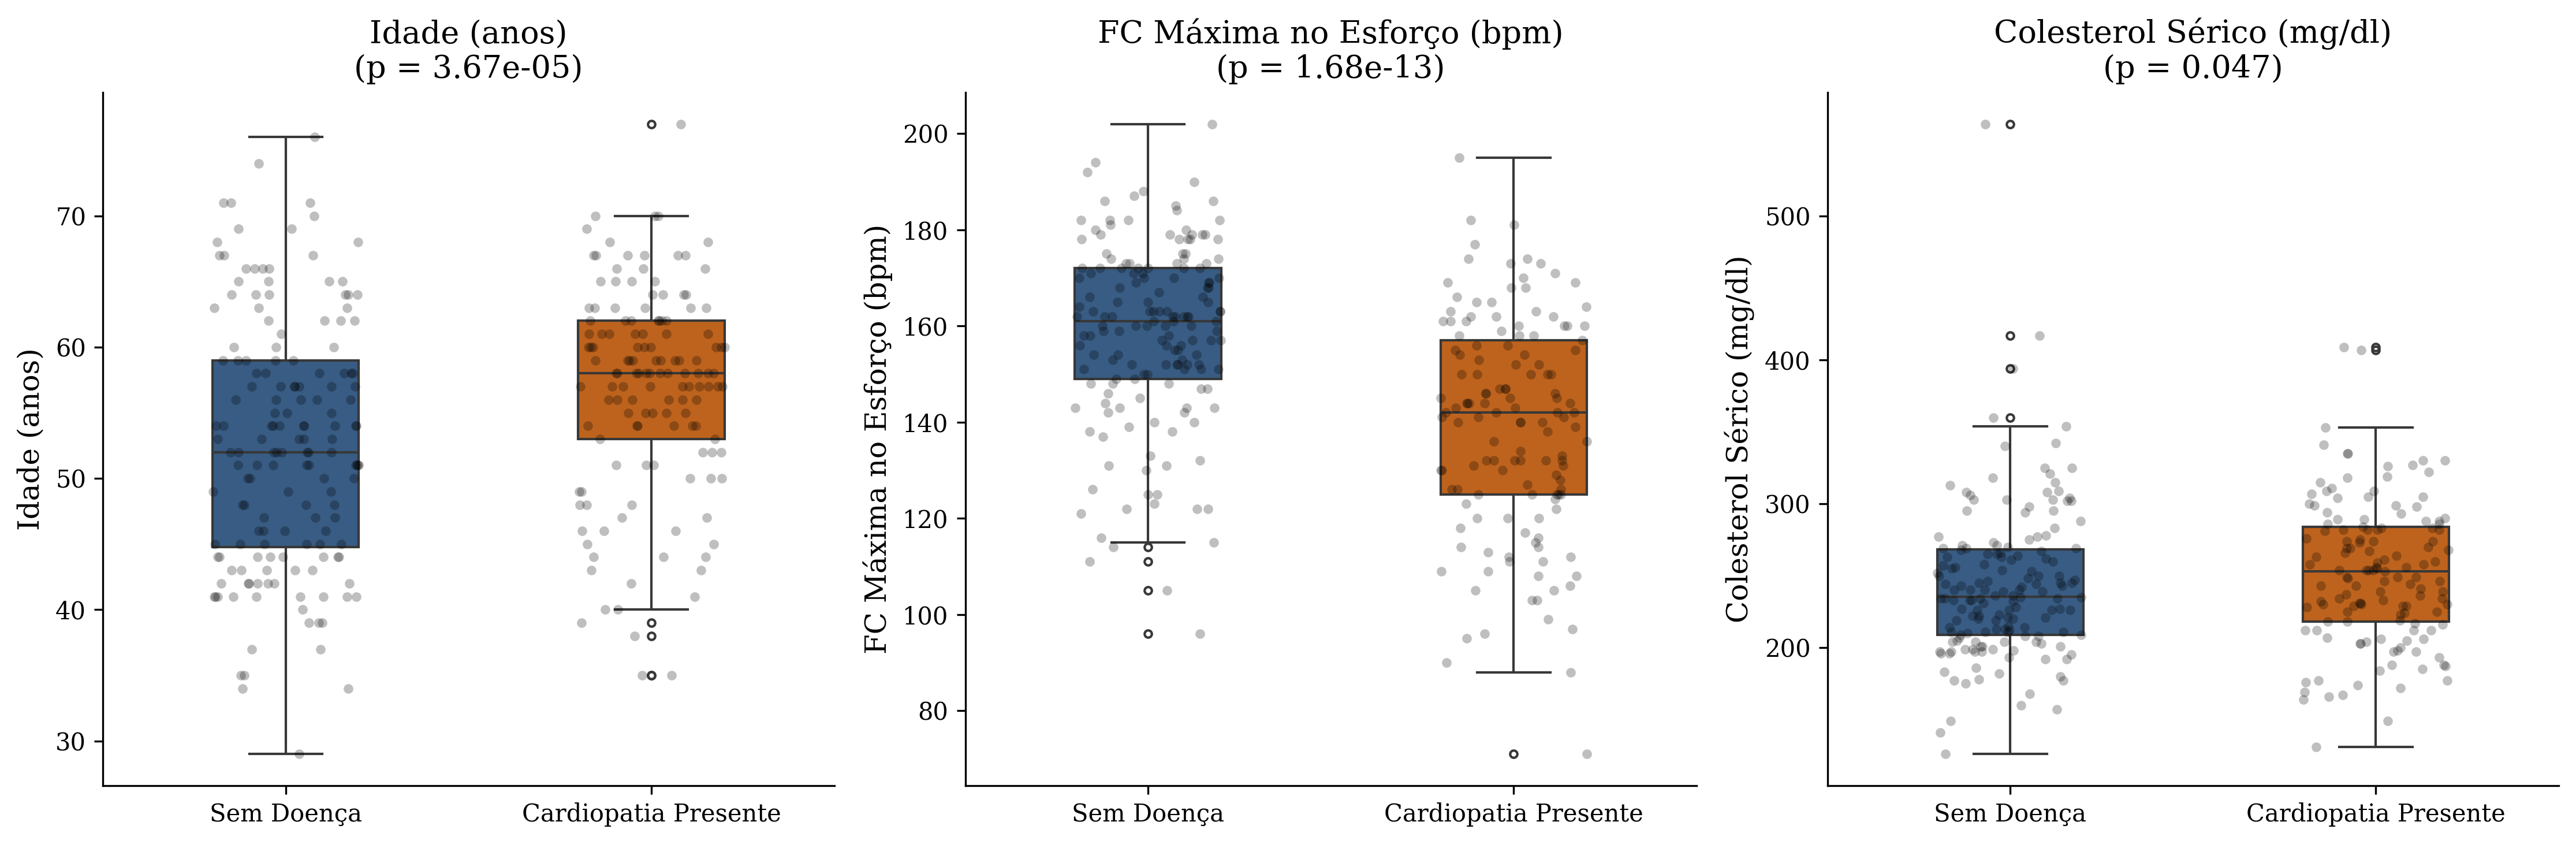

Figura salva com sucesso em: ../results/figures/fig01_biomarcadores_distribuicao.png


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração estética com foco em publicação científica
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 14,
    "figure.dpi": 300
})

FIGURES_DIR = os.path.join("..", "results", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

# 1. Painel Comparativo de Biomarcadores Contínuos
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
palette = ["#2b5c8f", "#d95f02"]  # Paleta sóbria e de alto contraste

variaveis_plot = [
    ("age", "Idade (anos)", "p = 3.67e-05"),
    ("thalach", "FC Máxima no Esforço (bpm)", "p = 1.68e-13"),
    ("chol", "Colesterol Sérico (mg/dl)", "p = 0.047")
]

for ax, (var, rotulo_y, p_text) in zip(axes, variaveis_plot):
    sns.boxplot(
        data=df, 
        x="outcome_label", 
        y=var, 
        palette=palette, 
        ax=ax, 
        width=0.4, 
        fliersize=3
    )
    sns.stripplot(
        data=df, 
        x="outcome_label", 
        y=var, 
        color="black", 
        alpha=0.25, 
        size=4, 
        jitter=0.2, 
        ax=ax
    )
    ax.set_title(f"{rotulo_y}\n({p_text})")
    ax.set_xlabel("")
    ax.set_ylabel(rotulo_y)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "fig01_biomarcadores_distribuicao.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Figura salva com sucesso em: {fig_path}")

In [10]:
# Tabela de contingência observada
contingency_sex = pd.crosstab(df["sex_label"], df["outcome_label"], margins=True)
print("=== Tabela de Contingência: Sexo Biológico vs Cardiopatia ===")
print(contingency_sex)

# Teste Qui-Quadrado de Pearson
chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(
    pd.crosstab(df["sex_label"], df["outcome_label"])
)

print(f"\nQui-Quadrado: {chi2_stat:.4f} | Graus de Liberdade: {dof} | p-valor: {p_val_chi2:.4e}")
if p_val_chi2 < 0.05:
    print("Resultado: Há associação estatisticamente significante entre sexo e prevalência de cardiopatia nesta coorte.")

=== Tabela de Contingência: Sexo Biológico vs Cardiopatia ===
outcome_label  Cardiopatia Presente  Sem Doença  All
sex_label                                           
Feminino                         25          71   96
Masculino                       112          89  201
All                             137         160  297

Qui-Quadrado: 21.8516 | Graus de Liberdade: 1 | p-valor: 2.9457e-06
Resultado: Há associação estatisticamente significante entre sexo e prevalência de cardiopatia nesta coorte.


In [11]:
DATA_PROC_DIR = os.path.join("..", "data", "processed")
os.makedirs(DATA_PROC_DIR, exist_ok=True)

processed_file = os.path.join(DATA_PROC_DIR, "heart_disease_cleaned.csv")
df.to_csv(processed_file, index=False)
print(f"Dataset tratado e anotado salvo em: {processed_file}")

Dataset tratado e anotado salvo em: ../data/processed/heart_disease_cleaned.csv
